# 3. Does the signal lower the cost of trading that must happen anyway?

A desk that has to buy or sell a fixed quantity pays the spread no matter what. A forecast that cannot pay for its own trades might still tell it **when** to send each piece.

**Design** (frozen before the second test period was downloaded; `orderflow/execution.py`):

- a parent order of 0.3 BTC, buy or sell, is split into 60 market-order children of 0.005 BTC, one per 10-second slot (10 minutes);
- parents start at hh:05 and hh:35 every hour, on both sides: 96 parents a day, 4,320 over the 45 days;
- *signal* schedule: inside each slot, wait while the forecast says the price is moving in our favour ($\sigma f_t < 0$), for at most 9 s;
- benchmarks: *TWAP* (send at the start of each slot), *random* (random delays drawn from the signal's own delay distribution, 20 draws) and *shift* (the signal rule applied to a forecast circularly shifted by one to 23 hours, 20 draws: same timing pattern, no information);
- each child takes at most 10% of the visible top-5 depth and the rest is retried the next second; liquidity we took stays gone for 5 s; anything unfilled at the deadline is valued at the deadline mid plus a 50 bp penalty, for the signal schedule only.

The cost of a schedule is its implementation shortfall against the mid when the parent starts, $\mathrm{IS} = \sigma\,10^4 (\mathrm{VWAP} - m)/m$ in bp. For each parent, $\Delta_X = \mathrm{IS}_X - \mathrm{IS}_{\text{signal}}$, so positive means the signal saved money. The daily means of $\Delta$ against TWAP, random and shift are $D4_t, D5_t, D7_t$, and their means over the 45 days are $Q_4, Q_5, Q_7$.

**Interval rule:** moving-block day bootstrap (1, 2, 5) and $t$-interval at level $1 - 0.05/3$; *positive* only if every lower bound is above zero. The **joint reading** is the first row that applies:

| row | condition | reading |
|---|---|---|
| 3 | $Q_4, Q_5, Q_7$ all positive | execution value supported, consistent with forecast information |
| 4 | $Q_4, Q_5$ positive, $Q_7$ not | execution value supported, information not isolated |
| 5 | $Q_4$ positive, $Q_5$ not | timing effect without evidence of information |
| 6 | $Q_4$ negative | harmful |
| 7 | otherwise | inconclusive |

(Rows 1–2 cover unidentified results and more than 0.5% unresolved parents.)

T = 45 days, 4320 parents, 0 unresolved

Q4 saving vs TWAP             0.177 bp   bootstrap [0.160, 0.195], [0.155, 0.199], [0.151, 0.202]   t [0.159, 0.195]   -> pos
Q5 saving vs random timing    0.177 bp   bootstrap [0.160, 0.195], [0.154, 0.199], [0.151, 0.202]   t [0.158, 0.195]   -> pos
Q7 saving vs shifted placebo  0.177 bp   bootstrap [0.160, 0.196], [0.155, 0.199], [0.151, 0.202]   t [0.159, 0.196]   -> pos

joint reading (row 3): Execution value supported, consistent with forecast information


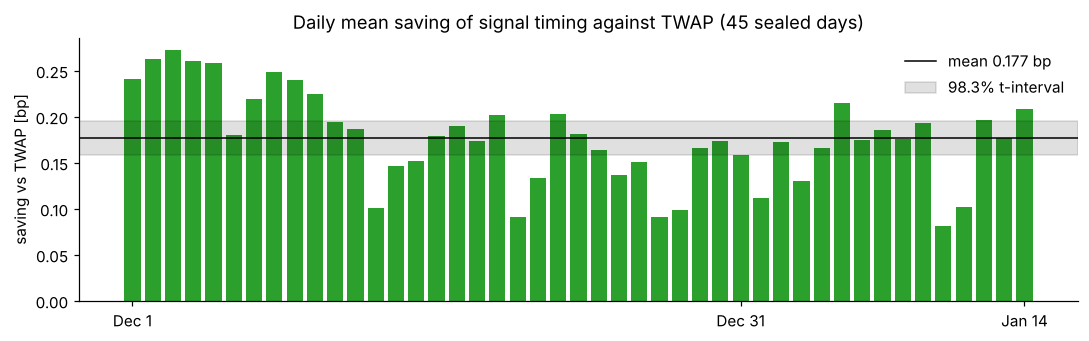

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':      # paths below are relative to the repository root
    os.chdir('..')
sys.path.insert(0, os.getcwd())
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from orderflow import stats

def read_csv(name):
    with open('results/' + name) as f:
        return list(csv.DictReader(f))

S = json.load(open('results/summary.json'))           # every number quoted in the README
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

rows = read_csv('execution_days.csv')
days = [{'eligible': int(r['eligible']), 'unresolved_parents': int(r['unresolved_parents']),
         **{k: float(r[k]) for k in ('D4', 'D5', 'D7', 'Q6')}} for r in rows]
res = stats.execution_study(days)
print(f"T = {res['T']} days, {res['eligible']} parents, {res['unresolved']} unresolved\n")
for q, name in (('Q4', 'saving vs TWAP'), ('Q5', 'saving vs random timing'), ('Q7', 'saving vs shifted placebo')):
    Q = res['quantities'][q]
    boot = ', '.join('[%.3f, %.3f]' % tuple(Q['bootstrap'][b]) for b in ('1', '2', '5'))
    print(f"{q} {name:26s} {Q['estimate']:.3f} bp   bootstrap {boot}   t [{Q['t_interval'][0]:.3f}, {Q['t_interval'][1]:.3f}]   -> {Q['class']}")
print('\njoint reading (row %d): %s' % (res['reading']['row'], res['reading']['text']))

E = S['execution_value']
assert res['quantities']['Q4']['estimate'] == E['Q4_vs_twap']['estimate']
assert res['reading']['text'] == E['reading']['text']

d4 = np.array([d['D4'] for d in days])
lo, hi = res['quantities']['Q4']['t_interval']
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(d4)), d4, color='tab:green')
ax.axhline(d4.mean(), color='k', lw=1, label=f'mean {d4.mean():.3f} bp')
ax.axhspan(lo, hi, color='k', alpha=0.12, label='98.3% t-interval')
ax.axhline(0, color='k', lw=0.6)
ax.set_xticks([0, 30, 44], ['Dec 1', 'Dec 31', 'Jan 14'])
ax.set_ylabel('saving vs TWAP [bp]')
ax.set_title('Daily mean saving of signal timing against TWAP (45 sealed days)')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig('figures/execution_daily.png')

All three savings are robustly positive and nearly equal. Random timing with the same delay distribution and the shifted placebo both do no better than TWAP, so the saving comes from the information in the forecast, not from the waiting pattern.

## Descriptive checks (not part of the test)

signal-free schedules minus TWAP (bp): {'random': -0.0003, 'shift': 0.0003, 'uniform': -0.0002, 'negated': 0.1776}
saving vs TWAP by latency: {'lat0': 0.22, 'base': 0.177, 'lat500': 0.103, 'lat1000': 0.068}
saving vs TWAP by liquidity refill time tau: {'tau0': 0.177, 'tau1': 0.177, 'base': 0.177, 'tau30': 0.177}
weekly mean saving: {'2025-W49': 0.242, '2025-W50': 0.191, '2025-W51': 0.16, '2025-W52': 0.146, '2026-W01': 0.154, '2026-W02': 0.161, '2026-W03': 0.194}


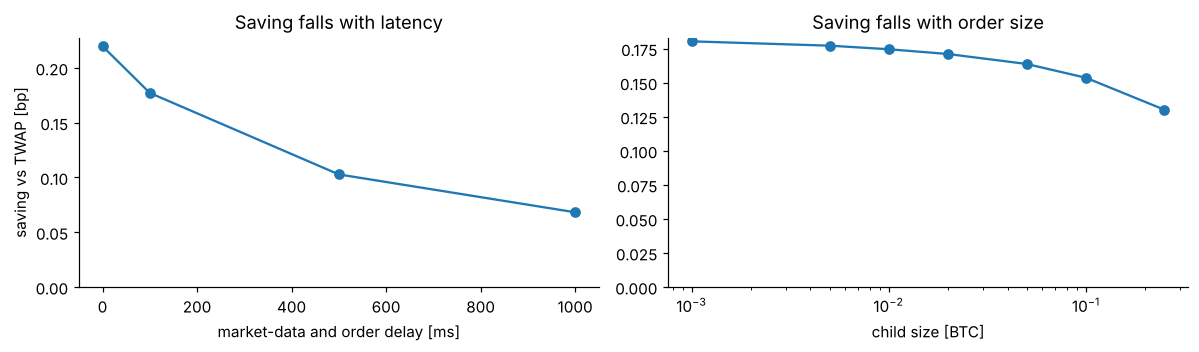

In [2]:
print('signal-free schedules minus TWAP (bp):', {k.replace('IS_', '').replace('-twap', ''): round(v, 4)
                                                  for k, v in E['descriptive_is_minus_twap_base'].items()})
lat = E['descriptive_D4_by_latency']
cap = E['capacity_line']
print('saving vs TWAP by latency:', {k: round(v, 3) for k, v in lat.items()})
print('saving vs TWAP by liquidity refill time tau:', {k: round(v, 3) for k, v in E['descriptive_D4_by_tau'].items()})
print('weekly mean saving:', {k: round(v, 3) for k, v in E['weekly_D4'].items()})

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot([0, 100, 500, 1000], [lat[k] for k in ('lat0', 'base', 'lat500', 'lat1000')], 'o-')
ax[0].set_xlabel('market-data and order delay [ms]')
ax[0].set_ylabel('saving vs TWAP [bp]')
ax[0].set_title('Saving falls with latency')
q = sorted(cap, key=int)
ax[1].plot([int(x) / 1000 for x in q], [cap[x]['D4'] for x in q], 'o-', label='saving vs TWAP')
ax[1].set_xscale('log')
ax[1].set_xlabel('child size [BTC]')
ax[1].set_title('Saving falls with order size')
for a in ax:
    a.set_ylim(0, None)
fig.tight_layout()
fig.savefig('figures/execution_sensitivity.png')

Using the forecast backwards (*negated*) costs about as much as using it correctly saves, while every signal-free schedule matches TWAP to within 0.0003 bp. The saving shrinks with latency and with child size: at 250 lots (0.25 BTC per child) the cap binds on more than half of the signal's submissions.

**Conclusion.** The forecast has execution value: about 0.18 bp of parent notional against TWAP, random timing and a placebo, robust on 45 later days. This holds for the tested size (0.3 BTC parents); without an impact model it cannot be scaled to larger orders. It lowers the cost of trading that has to happen anyway; it is not standalone alpha.

**Limitations.** The replay has no market impact or book reaction to our orders, no queue position and no hidden liquidity, so results apply only to the small orders tested; the 5 s refill is a crude sensitivity, not an impact model. We use market orders only. The book is conflated to 100 ms, latencies are assumed rather than measured, and we study one venue and one instrument. Nothing here is evidence of live profitability.